## Классификация моделей автомобилей | Грудинин Михаил 23Б16

## Данные

[Stanford Cars на Kaggle](https://www.kaggle.com/datasets/jutrera/stanford-car-dataset-by-classes-folder)

- **Задача** — определить по фотографии автомобиля его модель (один из 196 классов).
- **Train** — 8 144 снимка. из них:
  - `labeled` — 4 845 снимков для обучения. на класс приходится от 14 до 41 снимка, медиана — 25.
  - `hidden` — 2 077 снимков со скрытыми метками для псевдолейблинга.
  - `validation` — 1 222 снимка для выбора модели и лучшей эпохи.
- **Test** — 8 041 снимок для итоговой оценки.

в каждой части представлены все 196 классов. 

## Эксперимент

- **Модели** — ResNet-18, EfficientNet-B0 и ConvNeXt-Tiny.
- **Режимы обучения**:
  1. `baseline` — обучаем всю сеть с первой эпохи без аугментаций.
  2. `unfreeze` — начинаем с классификатора, постепенно размораживая всю сеть.
  3. `augment` — к разморозке добавляем итеративные аугментации:
     - эпохи 1–4: RandomHorizontalFlip(p=0.5)
     - эпохи 5–8: все предыдущее + RandomAffine(degrees=5, translate=(0.035, 0.035))
     - эпохи 9–12: все предыдущее + RandomAffine(degrees=9, translate=(0.065, 0.065)) и ColorJitter(brightness=0.2, contrast=0.2, saturation=0.12)
  4. `pseudo` — к режиму `augment` добавляем псевдоразметку: в начале 9-й эпохи модель предсказывает метки изображений из неразмеченного пула `hidden`. Принимаются только предсказания с уверенностью не ниже 0.60.
- **Условия сравнения** — одно разбиение и 12 эпох для всех запусков. внутри каждой архитектуры все четыре режима стартуют с одинаковых весов.

| Режим | Разморозка | Аугментации | Псевдометки | Адаптивный LR |
|---|---|---|---|---|
| baseline | Сразу вся сеть | Нет | Нет | Нет |
| unfreeze | Постепенная | Нет | Нет | Да |
| augment | Постепенная | Итеративные | Нет | Да |
| pseudo | Постепенная | Итеративные | Да | Да |

### Импорт библиотек

In [1]:
import random
import sys
from dataclasses import dataclass
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset, RandomSampler
from torchvision import models
from torchvision import transforms as T
from tqdm.auto import tqdm

### Конфигурация

In [2]:
DATA_DIR = Path("data/stanford_cars")
SEEDS = [42]
EPOCHS = 12
BATCH = 32
THRESHOLD = 0.60
SPLIT_SEED = 904
WORKERS = 2 if sys.platform.startswith("linux") else 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
amp = device.type == "cuda"
ARCHS = ["resnet18", "efficientnet_b0", "convnext_tiny"]
MODES = ["baseline", "unfreeze", "augment", "pseudo"]

### Скачивание датасета

Скачиваем Stanford Cars с Kaggle в локальную папку `data/stanford_cars`.

In [3]:
if not DATA_DIR.is_dir():
    url = (
        "https://www.kaggle.com/api/v1/datasets/download/"
        "jutrera/stanford-car-dataset-by-classes-folder"
    )
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=DATA_DIR.parent) as tmp:
        archive = Path(tmp) / "cars.zip"
        urlretrieve(url, archive)
        with ZipFile(archive) as dataset_zip:
            dataset_zip.extractall(Path(tmp) / "photos")
        train_dir = next(
            path for path in (Path(tmp) / "photos").rglob("train")
            if (path.parent / "test").is_dir()
        )
        train_dir.parent.rename(DATA_DIR)

names = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())


def split_frame(split: str) -> pd.DataFrame:
    rows = [
        (path, label)
        for label, name in enumerate(names)
        for path in sorted((DATA_DIR / split / name).iterdir())
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    return pd.DataFrame(rows, columns=["path", "label"])

### Разбиение датасета

In [4]:
train = split_frame("train")
test = split_frame("test")

dev, val = train_test_split(
    train, test_size=0.15, stratify=train.label, random_state=SPLIT_SEED
)
labeled, hidden = train_test_split(
    dev, test_size=0.30, stratify=dev.label, random_state=SPLIT_SEED
)

# The pseudo-labeling pool does not expose the true hidden labels.
pool = hidden[["path"]].assign(label=-1)

assert len(train) == len(labeled) + len(hidden) + len(val)
assert set(labeled.path).isdisjoint(hidden.path)
assert set(labeled.path).isdisjoint(val.path)
assert set(hidden.path).isdisjoint(val.path)
assert set(train.path).isdisjoint(test.path)

parts = {
    "Original train": train,
    "Labeled": labeled,
    "Hidden": hidden,
    "Validation": val,
    "Test": test,
}
summary_rows = []
for split, frame in parts.items():
    per_class = frame.label.value_counts()
    summary_rows.append(
        {
            "Split": split,
            "Images": len(frame),
            "Classes": len(per_class),
            "Min / class": per_class.min(),
            "Median / class": per_class.median(),
            "Max / class": per_class.max(),
        }
    )

split_summary = pd.DataFrame(summary_rows).set_index("Split")
display(
    split_summary.style
    .format(
        {
            "Images": "{:,.0f}",
            "Classes": "{:,.0f}",
            "Min / class": "{:,.0f}",
            "Median / class": "{:.1f}",
            "Max / class": "{:,.0f}",
        }
    )
    .bar(subset=["Images"], color="#c9dff2")
    .set_caption("Dataset splits and class balance")
)

,Images,Classes,Min / class,Median / class,Max / class
Split,,,,,
Original train,"8,144",196,24,42.0,68
Labeled,"4,845",196,14,25.0,41
Hidden,"2,077",196,6,11.0,17
Validation,"1,222",196,4,6.0,10
Test,"8,041",196,24,42.0,68


### Примеры сэмплов

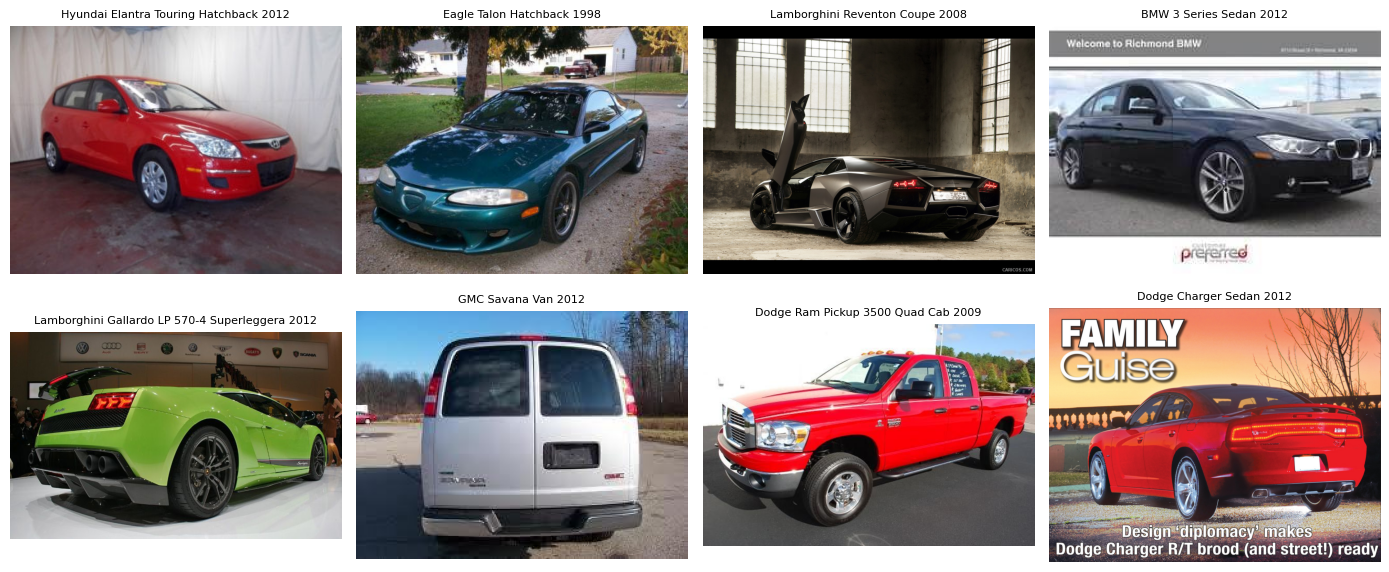

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, row in zip(
    axes.flat,
    labeled.sample(min(8, len(labeled)), random_state=SPLIT_SEED).itertuples(),
):
    with Image.open(row.path) as img:
        ax.imshow(img)
    ax.set_title(names[row.label], fontsize=8, wrap=True)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Подготовка изображений и батчей

- `Cars` читает фотографию с диска и приводит её к размеру 224 × 224 с сохранением пропорций.
- `transform` переводит изображение в тензор и нормализует его.
- `loader` собирает батчи по 32 изображения. для обучения размеченные снимки перемешиваются, а снимки с псевдометками выбираются с возвращением.

In [6]:
normalization = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])


def transform(level: int) -> T.Compose:
    ops = []
    if level >= 0:
        ops += [T.RandomHorizontalFlip()]
    if level >= 1:
        ops += [
            T.RandomAffine(
                5 if level == 1 else 9,
                translate=(0.035, 0.035) if level == 1 else (0.065, 0.065),
                fill=(124, 116, 104),
            )
        ]
    if level == 2:
        ops += [T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.12)]
    return T.Compose(ops + [T.ToTensor(), normalization])


class Cars(Dataset):
    def __init__(self, frame: pd.DataFrame, level: int) -> None:
        self.paths = frame.path.tolist()
        self.labels = frame.label.tolist()
        self.transform = transform(level)

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        with Image.open(self.paths[index]) as img:
            rgb = ImageOps.exif_transpose(img).convert("RGB")
            square = ImageOps.pad(
                rgb,
                (224, 224),
                method=Image.Resampling.BILINEAR,
                color=(124, 116, 104),
            )
            return self.transform(square), self.labels[index]


def loader(
    frame: pd.DataFrame,
    level: int = -1,
    seed: int = 0,
    shuffle: bool = False,
    samples: int | None = None,
) -> DataLoader:
    data = Cars(frame, level)
    gen = torch.Generator().manual_seed(seed)
    sampler = None
    if samples is not None:
        sampler = RandomSampler(
            data, replacement=True, num_samples=samples, generator=gen
        )
    return DataLoader(
        data,
        batch_size=BATCH,
        shuffle=shuffle,
        sampler=sampler,
        num_workers=WORKERS,
        pin_memory=amp,
        generator=gen,
    )

## Подготовка моделей

- `build` создаёт выбранную сеть и заменяет последний слой классификатором на 196 классов.
- `set_train_stage` открывает нужные группы блоков. у замороженных блоков веса остаются фиксированными, а BatchNorm сохраняет накопленную статистику.
- `predict` возвращает предсказанный класс и уверенность модели.
- `metrics` считает accuracy, macro-F1 и balanced accuracy.

In [7]:
def build(
    arch: str, pretrained: bool = True
) -> tuple[nn.Module, dict[str, list[nn.Module]]]:
    if arch == "resnet18":
        net = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT if pretrained else None
        )
        net.fc = nn.Linear(net.fc.in_features, len(names))
        groups = {
            "stem+layer1": [net.conv1, net.bn1, net.layer1],
            "layer2": [net.layer2],
            "layer3": [net.layer3],
            "layer4": [net.layer4],
            "fc": [net.fc],
        }
    elif arch == "efficientnet_b0":
        net = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
            if pretrained
            else None
        )
        net.classifier[-1] = nn.Linear(
            net.classifier[-1].in_features, len(names)
        )
        features = list(net.features.children())
        assert len(features) == 9
        groups = {
            "stem+stages1-2": features[:3],
            "stages3-4": features[3:5],
            "stages5-6": features[5:7],
            "stage7+projection": features[7:],
            "classifier": [net.classifier],
        }
    elif arch == "convnext_tiny":
        weights = models.ConvNeXt_Tiny_Weights.DEFAULT if pretrained else None
        net = models.convnext_tiny(weights=weights)
        net.classifier[-1] = nn.Linear(
            net.classifier[-1].in_features, len(names)
        )
        features = list(net.features.children())
        assert len(features) == 8
        groups = {
            "stem+stage1": features[:2],
            "down+stage2": features[2:4],
            "down+stage3": features[4:6],
            "down+stage4": features[6:],
            "classifier": [net.classifier],
        }
    else:
        raise ValueError(arch)
    assigned = [
        id(p) for modules in groups.values() for p in group_params(modules)
    ]
    assert len(assigned) == len(set(assigned)) == len(list(net.parameters()))
    return net.to(device), groups


def group_params(modules: list[nn.Module]) -> list[nn.Parameter]:
    return [param for module in modules for param in module.parameters()]


def set_train_stage(
    net: nn.Module, groups: dict[str, list[nn.Module]], active_count: int
) -> None:
    net.train()
    for depth, modules in enumerate(groups.values()):
        active = depth >= len(groups) - active_count
        for module in modules:
            module.requires_grad_(active)
            module.train(active)  # Keep frozen normalization statistics fixed.


@torch.inference_mode()
def predict(
    net: nn.Module, frame: pd.DataFrame
) -> tuple[np.ndarray, np.ndarray]:
    net.eval()
    predictions, confidences = [], []
    for x, _ in loader(frame):
        prob = net(x.to(device)).softmax(1)
        conf, pred = prob.max(1)
        predictions.extend(pred.cpu().tolist())
        confidences.extend(conf.cpu().tolist())
    return np.array(predictions), np.array(confidences)


def metrics(y: pd.Series, pred: np.ndarray) -> dict[str, float]:
    return dict(
        accuracy=accuracy_score(y, pred),
        macro_f1=f1_score(y, pred, average="macro"),
        balanced_accuracy=balanced_accuracy_score(y, pred),
    )

## Архитектуры и порядок разморозки

### 1. ResNet-18

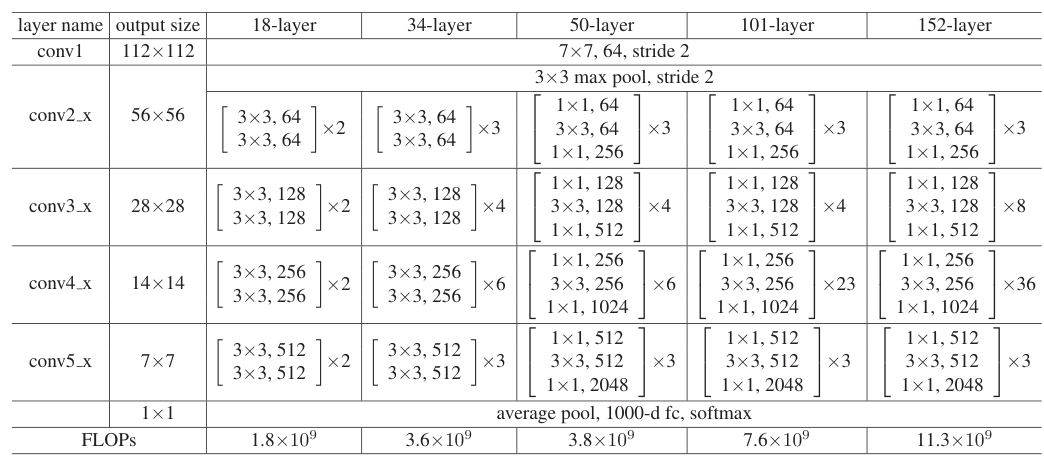

столбец **18-layer** описывает ResNet-18. обозначение ×2 означает два остаточных блока по две свёртки 3 × 3.

| эпоха | что подключаем к обучению |
|---|---|
| 1 | только `fc`, линейный классификатор |
| 2 | `layer4` — два последних блока, 512 каналов |
| 3 | `layer3` — два блока на 256 каналов |
| 4 | `layer2` — два блока на 128 каналов |
| 5 | `layer1` — два блока на 64 канала, а также входную свёртку 7 × 7 и её BatchNorm |

https://arxiv.org/pdf/1512.03385

### 2. EfficientNet-B0

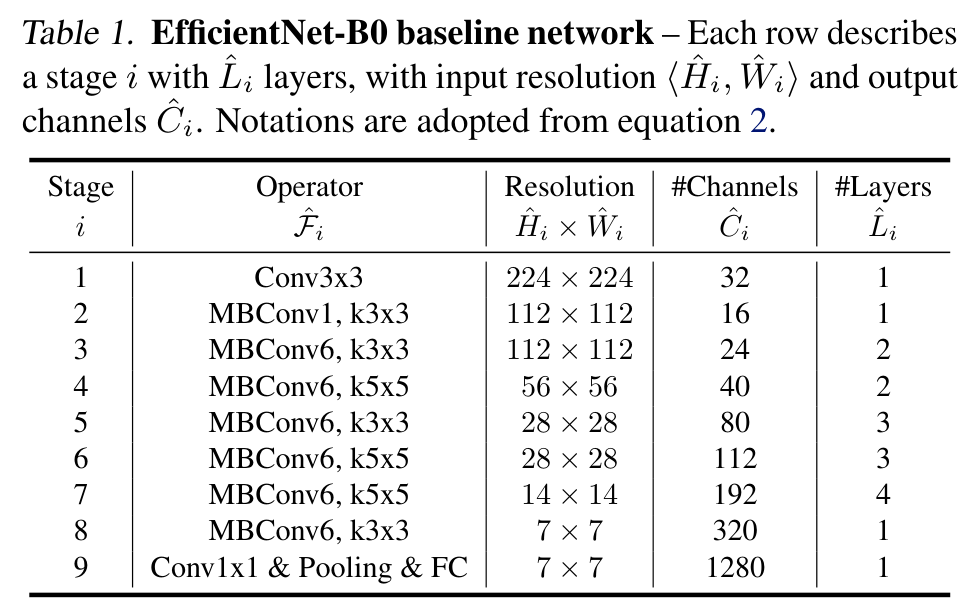

семь групп MBConv занимают строки 2–8. последний столбец показывает число блоков в группе.

| эпоха | что подключаем к обучению |
|---|---|
| 1 | только классификатор |
| 2 | последний MBConv на 320 каналов и следующую за ним свёртку 1 × 1, которая расширяет представление до 1280 каналов |
| 3 | 3 блока на 112 каналов и 4 блока на 192 канала |
| 4 | 2 блока на 40 каналов и 3 блока на 80 каналов |
| 5 | входную свёртку, первый MBConv на 16 каналов и 2 блока на 24 канала |

https://proceedings.mlr.press/v97/tan19a/tan19a.pdf

### 3. ConvNeXt-Tiny

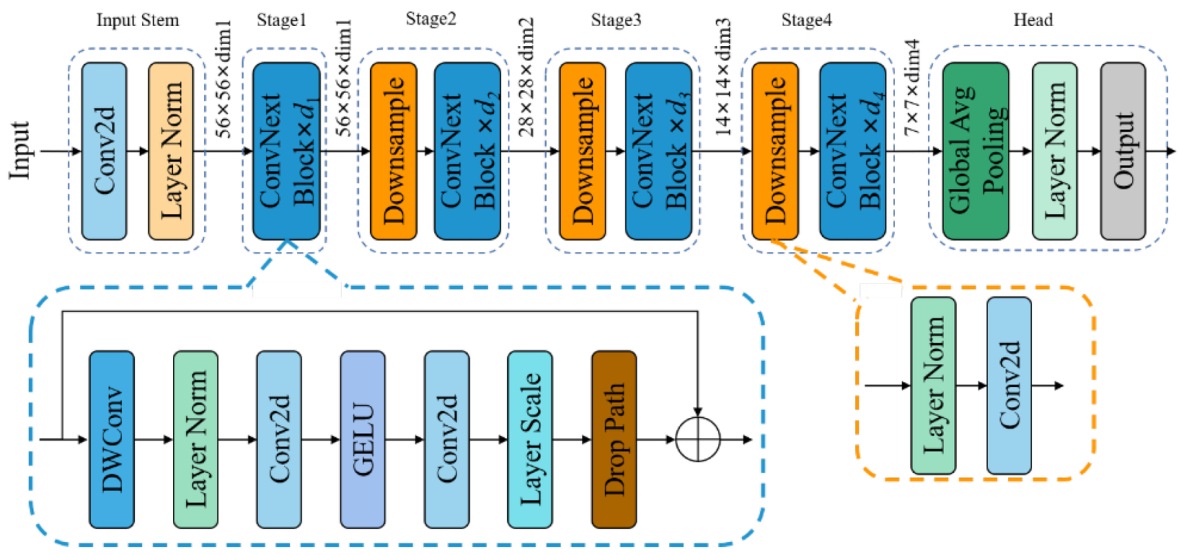

синие пунктирные рамки на схеме обозначают четыре стадии. для версии Tiny в них **3, 3, 9 и 3 блока**. оранжевый `Downsample` — переход между соседними стадиями. например, перед четвёртой стадией он превращает карту признаков размером 14 × 14 с 384 каналами в карту 7 × 7 с 768 каналами. в коде `down+stage4` означает, что мы одновременно открываем этот переход и все три блока после него.

| эпоха | что подключаем к обучению |
|---|---|
| 1 | только классификатор, включая его финальную нормализацию |
| 2 | переход к 4-й стадии и все её 3 блока на 768 каналов |
| 3 | переход к 3-й стадии и все её 9 блоков на 384 канала |
| 4 | переход ко 2-й стадии и все её 3 блока на 192 канала |
| 5 | входную свёртку 4 × 4 с нормализацией и все 3 блока 1-й стадии на 96 каналов |

https://www.mdpi.com/2304-8158/13/6/925

### Доля обучаемых параметров

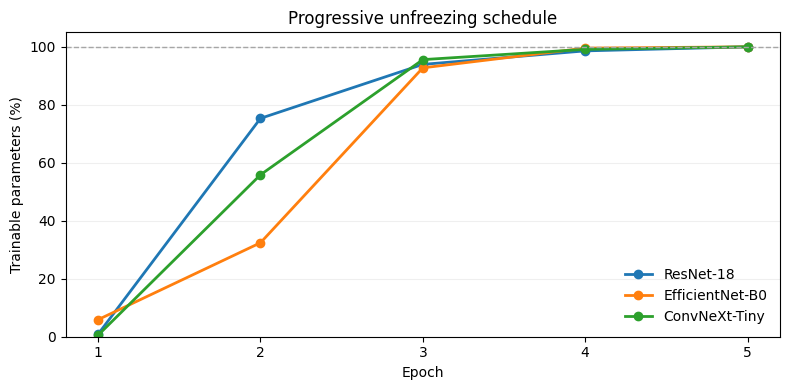

In [8]:
unfreeze_rows = []
for arch in ARCHS:
    preview, blocks = build(arch, pretrained=False)
    total_params = sum(p.numel() for p in preview.parameters())
    trainable_params = 0
    for epoch, modules in enumerate(reversed(list(blocks.values())), 1):
        trainable_params += sum(p.numel() for p in group_params(modules))
        unfreeze_rows.append(
            (arch, epoch, 100 * trainable_params / total_params)
        )
    del preview, blocks

unfreeze_schedule = pd.DataFrame(
    unfreeze_rows, columns=["arch", "epoch", "trainable_pct"]
)

fig, ax = plt.subplots(figsize=(8, 4))
model_labels = {
    "resnet18": "ResNet-18",
    "efficientnet_b0": "EfficientNet-B0",
    "convnext_tiny": "ConvNeXt-Tiny",
}
for arch, frame in unfreeze_schedule.groupby("arch", sort=False):
    ax.plot(
        frame.epoch,
        frame.trainable_pct,
        marker="o",
        linewidth=2,
        label=model_labels[arch],
    )
ax.axhline(100, color="0.65", linestyle="--", linewidth=1)
ax.set(
    xlabel="Epoch",
    ylabel="Trainable parameters (%)",
    title="Progressive unfreezing schedule",
    xticks=range(1, 6),
    ylim=(0, 105),
)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Цикл обучения

- `train_epoch` выполняет одну эпоху. в режиме `pseudo` с 9-й эпохи к ошибке на размеченном батче добавляется ошибка на псевдометках с весом 0,5.
- `run` обучает одну модель в одном режиме, управляет разморозкой и аугментациями.

In [ ]:
def train_epoch(
    net: nn.Module,
    opt: torch.optim.Optimizer,
    supervised: DataLoader,
    extra: DataLoader | None,
    scaler: torch.amp.GradScaler,
) -> float:
    extras = iter(extra) if extra is not None else None
    total, seen = 0.0, 0
    for x, y in supervised:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
            loss = nn.functional.cross_entropy(net(x), y)
            if extras is not None:
                ux, uy = next(extras)
                loss = loss + 0.5 * nn.functional.cross_entropy(
                    net(ux.to(device)), uy.to(device)
                )
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total += loss.item() * len(y)
        seen += len(y)
    return total / seen


@dataclass
class RunResult:
    history: pd.DataFrame
    weights: dict[str, torch.Tensor]
    audit: pd.DataFrame | None


def run(arch: str, mode: str, seed: int) -> RunResult:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    net, groups = build(arch)
    opt = torch.optim.AdamW(
        net.parameters(), lr=3e-4,
        weight_decay=1e-4,
    )
    scheduler = None
    if mode != "baseline":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            opt, mode="max", patience=2, factor=0.5
        )
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    history, chosen = [], None
    audit = None
    best = -1.0
    progress = tqdm(range(EPOCHS), desc=f"{arch} | {mode}", leave=True)
    for epoch in progress:
        stage = min(2, 3 * epoch // EPOCHS)
        # Match the labeled batch order across modes.
        epoch_seed = 1000 * seed + epoch
        level = stage if mode in ("augment", "pseudo") else -1
        if mode == "pseudo" and stage == 2 and chosen is None:
            pred, conf = predict(net, pool)
            audit = pool.assign(
                label=pred, confidence=conf, accepted=conf >= THRESHOLD
            )
            chosen = audit.loc[audit.accepted]
            tqdm.write(
                f"Pseudo-labels accepted: {len(chosen)}/{len(pool)} "
                f"| predicted classes: {chosen.label.nunique()}",
                file=sys.stderr,
            )
        active_count = (
            len(groups) if mode == "baseline" else min(epoch + 1, len(groups))
        )
        set_train_stage(net, groups, active_count)
        supervised = loader(labeled, level, epoch_seed, shuffle=True)
        extra = None
        if chosen is not None and len(chosen):
            extra = loader(
                chosen, level, epoch_seed + 100, samples=len(labeled)
            )
        loss = train_epoch(net, opt, supervised, extra, scaler)
        predictions, _ = predict(net, val)
        scores = metrics(val.label, predictions)

        if scheduler is not None:
            scheduler.step(scores["accuracy"])

        if scores["accuracy"] > best:
            best = scores["accuracy"]
            best_weights = {
                key: value.detach().to("cpu", copy=True)
                for key, value in net.state_dict().items()
            }
        history.append(
            dict(
                epoch=epoch + 1,
                loss=loss,
                pseudo_count=0 if chosen is None else len(chosen),
                **scores,
            )
        )
        progress.set_postfix(
            loss=f"{loss:.3f}", val=f"{scores['accuracy']:.3f}"
        )
    tqdm.write(
        f"{arch} | {mode} | best val {best:.2%}",
        file=sys.stderr,
    )
    return RunResult(pd.DataFrame(history), best_weights, audit)

## Запуск экспериментов

`train_model` запускает для одной архитектуры четыре независимых обучения с одинаковыми начальными весами. ниже у каждой архитектуры своя ячейка с результатами.

In [10]:
def train_model(arch: str) -> dict[tuple[str, str, int], RunResult]:
    return {
        (arch, mode, seed): run(arch, mode, seed)
        for seed in SEEDS
        for mode in MODES
    }


runs: dict[tuple[str, str, int], RunResult] = {}

## Обучение ResNet-18

In [11]:
runs.update(train_model("resnet18"))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s] 


resnet18 | baseline:   0%|          | 0/12 [00:00<?, ?it/s]

resnet18 | baseline | best val 63.91%


resnet18 | unfreeze:   0%|          | 0/12 [00:00<?, ?it/s]

resnet18 | unfreeze | best val 60.97%


resnet18 | augment:   0%|          | 0/12 [00:00<?, ?it/s]

resnet18 | augment | best val 70.95%


resnet18 | pseudo:   0%|          | 0/12 [00:00<?, ?it/s]

Pseudo-labels accepted: 951/2077 | predicted classes: 189
resnet18 | pseudo | best val 67.02%


## Обучение EfficientNet-B0

In [12]:
runs.update(train_model("efficientnet_b0"))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


efficientnet_b0 | baseline:   0%|          | 0/12 [00:00<?, ?it/s]

efficientnet_b0 | baseline | best val 68.82%


efficientnet_b0 | unfreeze:   0%|          | 0/12 [00:00<?, ?it/s]

efficientnet_b0 | unfreeze | best val 73.08%


efficientnet_b0 | augment:   0%|          | 0/12 [00:00<?, ?it/s]

efficientnet_b0 | augment | best val 74.88%


efficientnet_b0 | pseudo:   0%|          | 0/12 [00:00<?, ?it/s]

Pseudo-labels accepted: 1288/2077 | predicted classes: 195
efficientnet_b0 | pseudo | best val 76.68%


## Обучение ConvNeXt-Tiny

In [13]:
runs.update(train_model("convnext_tiny"))

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 224MB/s] 


convnext_tiny | baseline:   0%|          | 0/12 [00:00<?, ?it/s]

convnext_tiny | baseline | best val 84.12%


convnext_tiny | unfreeze:   0%|          | 0/12 [00:00<?, ?it/s]

convnext_tiny | unfreeze | best val 84.04%


convnext_tiny | augment:   0%|          | 0/12 [00:00<?, ?it/s]

convnext_tiny | augment | best val 84.29%


convnext_tiny | pseudo:   0%|          | 0/12 [00:00<?, ?it/s]

Pseudo-labels accepted: 1537/2077 | predicted classes: 195
convnext_tiny | pseudo | best val 86.17%


## Динамика обучения

Best validation configuration: ('convnext_tiny', 'pseudo')


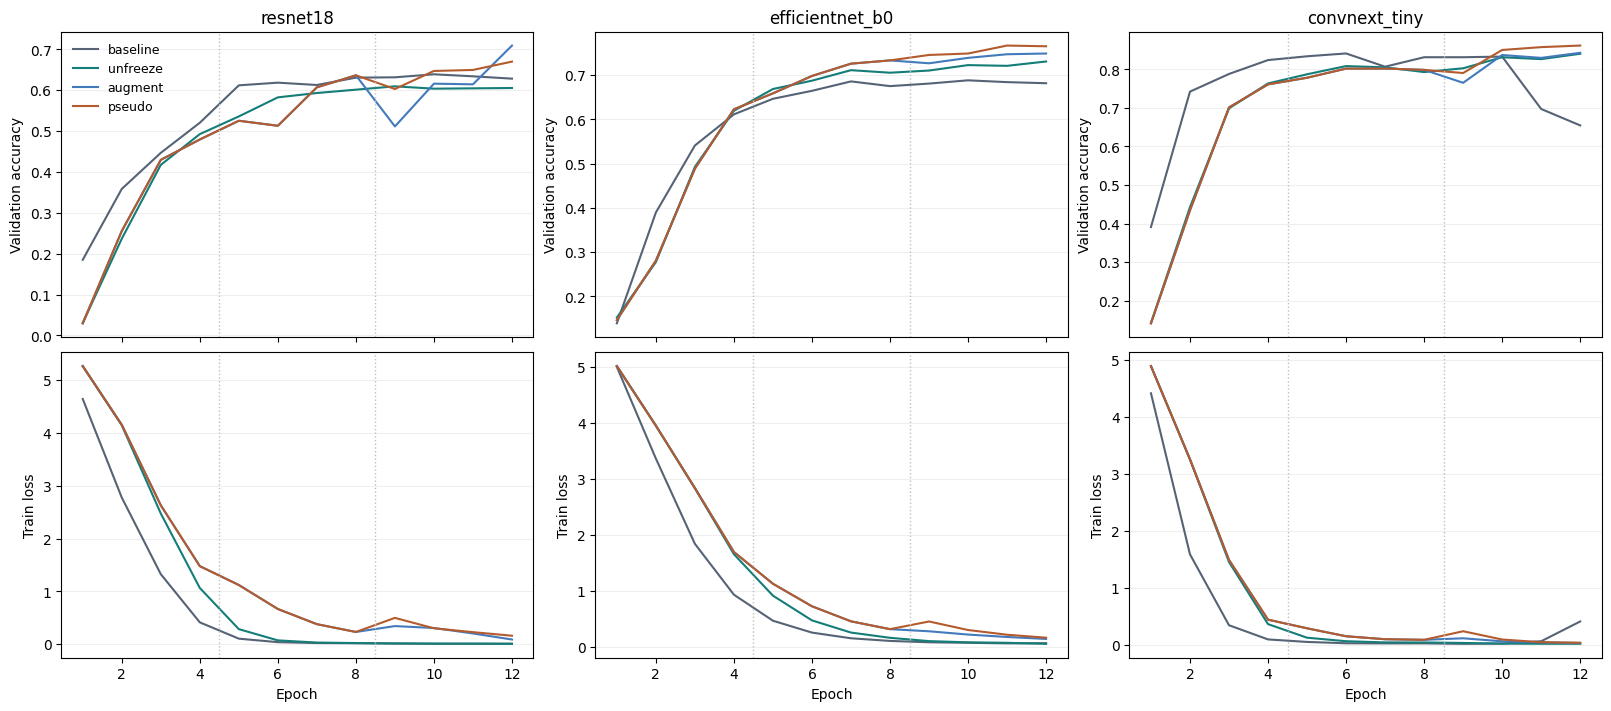

In [14]:
curves = pd.concat(
    [
        result.history.assign(arch=a, mode=m, seed=s)
        for (a, m, s), result in runs.items()
    ],
    ignore_index=True,
)
best_rows = curves.loc[
    curves.groupby(["arch", "mode", "seed"]).accuracy.idxmax()
]
winner = best_rows.groupby(["arch", "mode"]).accuracy.mean().idxmax()
print("Best validation configuration:", winner)

colors = dict(zip(MODES, ["#556375", "#147d78", "#427abb", "#b45b2e"]))
fig, axes = plt.subplots(
    2, len(ARCHS), figsize=(16, 7), sharex=True, layout="constrained"
)
for col, arch in enumerate(ARCHS):
    for mode in MODES:
        history = curves[
            (curves.arch == arch) & (curves["mode"] == mode)
        ].groupby("epoch")
        for row, metric in enumerate(["accuracy", "loss"]):
            values = history[metric].mean()
            axes[row, col].plot(
                values.index, values, color=colors[mode], label=mode
            )
    for ax in axes[:, col]:
        for boundary in [
            int(np.ceil(EPOCHS / 3)) + 0.5,
            int(np.ceil(2 * EPOCHS / 3)) + 0.5,
        ]:
            ax.axvline(boundary, color="0.75", linestyle=":", linewidth=1)
        ax.grid(axis="y", alpha=0.2)
    axes[0, col].set(title=arch, ylabel="Validation accuracy")
    axes[1, col].set(xlabel="Epoch", ylabel="Train loss")
axes[0, 0].legend(frameon=False, fontsize=9)
plt.show()

## Результаты на тесте

In [15]:
rows = []
for (arch, mode, seed), result in runs.items():
    net, _ = build(arch, pretrained=False)
    net.load_state_dict(result.weights)
    pred, conf = predict(net, test)
    hist = result.history
    best_row = hist.loc[hist.accuracy.idxmax()]
    rows.append(
        dict(
            arch=arch,
            mode=mode,
            seed=seed,
            epoch=int(best_row.epoch),
            val_accuracy=best_row.accuracy,
            pseudo_used=int(hist.pseudo_count.max()),
            **metrics(test.label, pred),
        )
    )
    del net
    if (arch, mode) == winner and seed == SEEDS[0]:
        errors = (
            test.assign(pred=pred, confidence=conf)
            .query("label != pred")
            .copy()
        )
        errors["true_model"] = errors.label.map(dict(enumerate(names)))
        errors["predicted_model"] = errors.pred.map(dict(enumerate(names)))
results = pd.DataFrame(rows)
results["mode"] = pd.Categorical(
    results["mode"], categories=MODES, ordered=True
)
results = results.sort_values(["arch", "seed", "mode"])
results["delta_accuracy_pp"] = (
    100 * results.groupby(["arch", "seed"]).accuracy.diff()
)
display(results.round(4))
if len(SEEDS) > 1:
    display(
        results.groupby(["arch", "mode"], observed=True)[
            ["accuracy", "macro_f1"]
        ].agg(["mean", "std"])
    )

,arch,mode,seed,epoch,val_accuracy,pseudo_used,accuracy,macro_f1,balanced_accuracy,delta_accuracy_pp
8,convnext_tiny,baseline,42,6,0.8412,0,0.8304,0.8295,0.8291,NaN
9,convnext_tiny,unfreeze,42,12,0.8404,0,0.8239,0.8225,0.8233,-0.6467
10,convnext_tiny,augment,42,12,0.8429,0,0.8418,0.8410,0.8410,1.7908
11,convnext_tiny,pseudo,42,12,0.8617,1537,0.8494,0.8486,0.8488,0.7586
4,efficientnet_b0,baseline,42,10,0.6882,0,0.6703,0.6678,0.6694,NaN
5,efficientnet_b0,unfreeze,42,12,0.7308,0,0.7201,0.7185,0.7198,4.9745
6,efficientnet_b0,augment,42,12,0.7488,0,0.7441,0.7418,0.7441,2.4002
7,efficientnet_b0,pseudo,42,11,0.7668,1288,0.7561,0.7550,0.7562,1.2063
0,resnet18,baseline,42,10,0.6391,0,0.6319,0.6291,0.6312,NaN
1,resnet18,unfreeze,42,9,0.6097,0,0.6085,0.6052,0.6069,-2.3380


### Сравнение точности по режимам

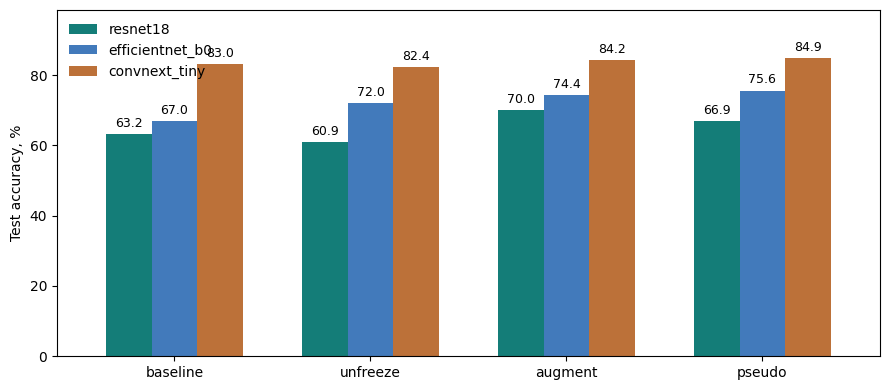

In [16]:
scores = (
    results.groupby(["mode", "arch"], observed=True)
    .accuracy.mean()
    .unstack()
    .loc[MODES, ARCHS]
    * 100
)
ax = scores.plot.bar(
    figsize=(9, 4), color=["#147d78", "#427abb", "#bc7139"], rot=0, width=0.7
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
ax.set(
    xlabel="",
    ylabel="Test accuracy, %",
    ylim=(0, max(10, scores.max().max() * 1.16)),
)
ax.legend(title=None, frameon=False)
ax.figure.tight_layout()
plt.show()

## Качество псевдометок

In [17]:
audit_rows = []
for (arch, mode, seed), result in runs.items():
    if mode != "pseudo":
        continue
    audit = result.audit.merge(
        hidden.rename(columns={"label": "truth"}),
        on="path",
        validate="one_to_one",
    )
    assert len(audit) == len(pool)
    accepted = audit.loc[audit.accepted]
    audit_rows.append(
        {
            "model": arch,
            "seed": seed,
            "accepted": len(accepted),
            "coverage": len(accepted) / len(pool),
            "classes": accepted.label.nunique(),
            "accuracy_accepted": accepted.label.eq(accepted.truth).mean(),
        }
    )
quality = pd.DataFrame(audit_rows)
display(quality.round(3))

,model,seed,accepted,coverage,classes,accuracy_accepted
0,resnet18,42,951,0.458,189,0.855
1,efficientnet_b0,42,1288,0.620,195,0.885
2,convnext_tiny,42,1537,0.740,195,0.904


## Ошибки классификации

Model: ConvNeXt-Tiny | Mode: pseudo


,,errors
Ground truth,Prediction,
Audi S5 Coupe 2012,Audi A5 Coupe 2012,18
Audi TTS Coupe 2012,Audi TT Hatchback 2011,18
Bentley Continental GT Coupe 2007,Bentley Continental GT Coupe 2012,18
Chevrolet Express Van 2007,Chevrolet Express Cargo Van 2007,18
Chevrolet Silverado 2500HD Regular Cab 2012,Chevrolet Silverado 1500 Regular Cab 2012,14
Chevrolet Tahoe Hybrid SUV 2012,Chevrolet Avalanche Crew Cab 2012,12
Audi V8 Sedan 1994,Audi 100 Sedan 1994,11
Dodge Caliber Wagon 2012,Dodge Caliber Wagon 2007,11
Suzuki SX4 Sedan 2012,Suzuki Aerio Sedan 2007,11


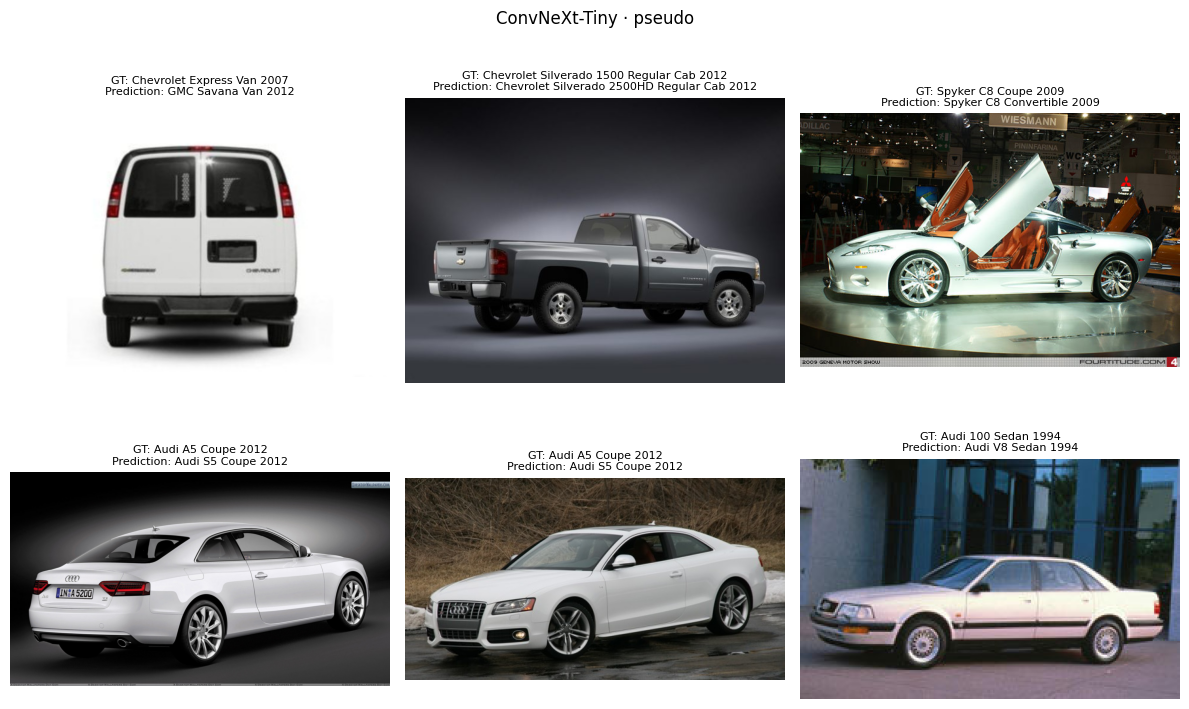

In [18]:
arch, mode = winner
model_name = {"resnet18": "ResNet-18", "efficientnet_b0": "EfficientNet-B0",
              "convnext_tiny": "ConvNeXt-Tiny"}[arch]
print(f"Model: {model_name} | Mode: {mode}")
display(
    errors.groupby(["true_model", "predicted_model"])
    .size()
    .nlargest(10)
    .rename("errors")
    .rename_axis(["Ground truth", "Prediction"])
    .to_frame()
)
if len(errors):
    examples = errors.nlargest(6, "confidence")
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, examples.itertuples()):
        with Image.open(row.path) as img:
            ax.imshow(img)
        ax.set_title(
            f"GT: {row.true_model}\n"
            f"Prediction: {row.predicted_model}",
            fontsize=8,
        )
    fig.suptitle(f"{model_name} · {mode}")
    fig.tight_layout()
    plt.show()

## Выводы

**Постепенная разморозка с адаптивным LR (`unfreeze` относительно `baseline`):**
- ResNet-18: −2.34 п.п.;
- EfficientNet-B0: +4.97 п.п.;
- ConvNeXt-Tiny: −0.65 п.п.

**Добавление итеративных аугментаций (`augment` относительно `unfreeze`):**
- ResNet-18: +9.19 п.п.;
- EfficientNet-B0: +2.40 п.п.;
- ConvNeXt-Tiny: +1.79 п.п.

**Добавление псевдоразметки (`pseudo` относительно `augment`):**
- ResNet-18: −3.12 п.п.;
- EfficientNet-B0: +1.21 п.п.;
- ConvNeXt-Tiny: +0.76 п.п.

Таким образом, режим с аугментациями обеспечивает прирост Accuracy для всех трёх архитектур. Постепенная разморозка без аугментаций улучшает качество только EfficientNet-B0, а псевдоразметка даёт дополнительный прирост только для EfficientNet-B0 и ConvNeXt-Tiny.

### Анализ псевдоразметки

При одинаковом трешхолде 0.6 архитектуры различаются по количеству и качеству принятых псевдометок:

- ResNet-18 принимает 951 изображение (45.8% неразмеченного пула) с точностью 85.5%.
- EfficientNet-B0 принимает 1 288 изображений (62.0%) с точностью 88.5%.
- ConvNeXt-Tiny: 1 537 изображений (74.0%) с точностью 90.4%.

Более сильная модель позволяет одновременно увеличить охват неразмеченных данных и снизить долю ошибочных псевдометок. Это согласуется с результатами тестирования, где псевдоразметка улучшает качество EfficientNet-B0 и ConvNeXt-Tiny, но не ResNet-18.


### Результаты анализа ошибок

Наиболее частые ошибки связаны с визуально похожими моделями и модификациями автомобилей.

Среди наиболее частых пар ошибок:
- Audi S5 Coupe 2012 → Audi A5 Coupe 2012: 18 ошибок;
- Audi TTS Coupe 2012 → Audi TT Hatchback 2011: 18 ошибок;
- Bentley Continental GT Coupe 2007 → Bentley Continental GT Coupe 2012: 18 ошибок;
- Chevrolet Express Van 2007 → Chevrolet Express Cargo Van 2007: 18 ошибок;
- Chevrolet Silverado 2500HD Regular Cab 2012 → Chevrolet Silverado 1500 Regular Cab 2012: 14 ошибок.

Это отражает специфику fine-grained classification: для различения классов необходимо учитывать небольшие детали внешнего вида, поколения и модификации автомобилей.

для ориентира, FC-CNN [D] получила 79,8% accuracy на Stanford Cars при другом протоколе обучения.
https://openaccess.thecvf.com/content_iccv_2015/papers/Lin_Bilinear_CNN_Models_ICCV_2015_paper.pdf